# SESSION 9 - Normal Distribution

This notebook contains the complete implementations, probability density visualizations, and empirical rule verifications for **Session 9 - Normal Distribution**.

### Covered Tasks:
1. **Task 1:** Generating 100 normally distributed random numbers ($\mu=50, \sigma=10$) with a fitted bell curve plot.
2. **Task 2:** Evaluating Mean, Median, and Mode equality ($\text{Mean} \approx \text{Median} \approx \text{Mode}$) on 20 fitness tracker daily step counts.
3. **Task 3:** Simulation of 200 online game scores ($\mu=70, \sigma=15$) and empirical verification of the **68-95-99.7 Rule** within $1\sigma$ ($55$ to $85$).
4. **Task 4:** Real-world modeling justification explaining why Spotify song durations follow a normal distribution.

## Task 1: Generate 100 Normally Distributed Numbers & Plot Bell Curve

**Prompt:** *Generate 100 random numbers in Python that follow a normal distribution with mean 50 and standard deviation 10 using numpy, then plot the bell curve using matplotlib.*

Task 1: Summary Statistics of 100 Generated Numbers
Target Distribution         : N(μ = 50, σ = 10)
Sample Mean (x̄)             : 48.96
Sample Standard Dev (s)     : 9.04
Minimum Value               : 23.80
Maximum Value               : 68.52


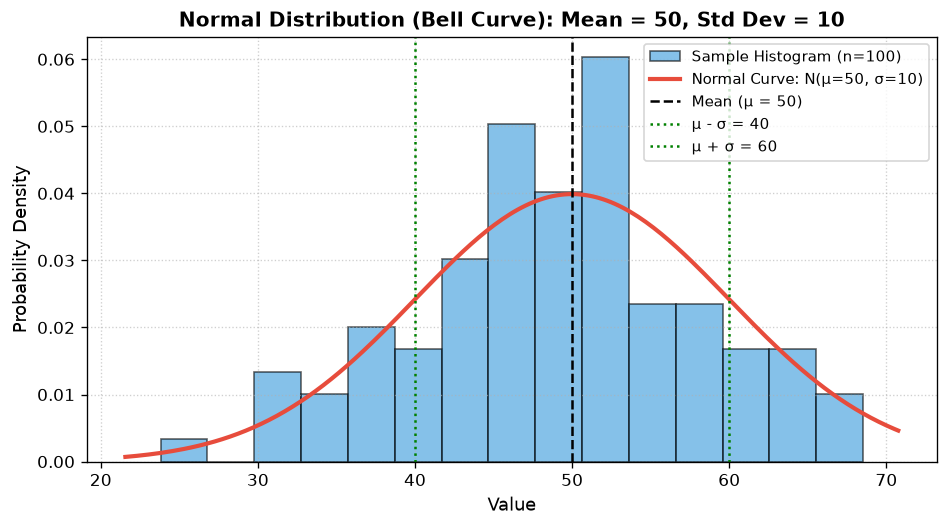

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Set seed for reproducible generation
np.random.seed(42)

# Parameters
mu = 50       # Mean
sigma = 10    # Standard Deviation
n_samples = 100

# Generate 100 random numbers from N(50, 10^2)
data_normal = np.random.normal(loc=mu, scale=sigma, size=n_samples)

# Plotting the Bell Curve
plt.figure(figsize=(8, 4.5))

# 1. Histogram of the generated sample data (normalized to density)
count, bins, ignored = plt.hist(data_normal, bins=15, density=True, alpha=0.6, color='#3498db', edgecolor='black', label='Sample Histogram (n=100)')

# 2. Theoretical Normal PDF curve
xmin, xmax = plt.xlim()
x_axis = np.linspace(xmin, xmax, 200)
pdf_curve = stats.norm.pdf(x_axis, loc=mu, scale=sigma)
plt.plot(x_axis, pdf_curve, color='#e74c3c', linewidth=2.5, label=f'Normal Curve: N(μ={mu}, σ={sigma})')

# Mark Mean and 1-StdDev lines
plt.axvline(mu, color='black', linestyle='--', linewidth=1.5, label=f'Mean (μ = {mu})')
plt.axvline(mu - sigma, color='green', linestyle=':', linewidth=1.5, label=f'μ - σ = {mu - sigma}')
plt.axvline(mu + sigma, color='green', linestyle=':', linewidth=1.5, label=f'μ + σ = {mu + sigma}')

plt.title("Normal Distribution (Bell Curve): Mean = 50, Std Dev = 10", fontsize=12, fontweight='bold')
plt.xlabel("Value", fontsize=11)
plt.ylabel("Probability Density", fontsize=11)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("normal_distribution_bell_curve.png", dpi=150)
plt.show()

print("=" * 65)
print("Task 1: Summary Statistics of 100 Generated Numbers")
print("=" * 65)
print(f"Target Distribution         : N(μ = {mu}, σ = {sigma})")
print(f"Sample Mean (x̄)             : {np.mean(data_normal):.2f}")
print(f"Sample Standard Dev (s)     : {np.std(data_normal):.2f}")
print(f"Minimum Value               : {np.min(data_normal):.2f}")
print(f"Maximum Value               : {np.max(data_normal):.2f}")


## Task 2: Mean, Median, and Mode in Fitness Step Counts

**Prompt:** *Given an array of 20 daily step counts from your fitness tracker app, calculate the mean, median, and mode, and check if they are approximately equal as expected in a normal distribution.*  
*Hint: Use `numpy.mean()`, `numpy.median()`, and `scipy.stats.mode()`.*

In [2]:
import numpy as np
import scipy.stats as stats

# 20 daily step counts from fitness tracker
step_counts = np.array([
    6800, 7100, 6950, 7200, 7000, 
    6850, 7050, 7150, 6900, 7000, 
    7300, 6700, 7050, 7000, 6950, 
    7100, 7000, 6900, 7250, 7050
])

# Calculate Central Tendency Metrics
mean_steps = float(np.mean(step_counts))
median_steps = float(np.median(step_counts))
mode_result = stats.mode(step_counts)
mode_steps = float(mode_result.mode)

print("=" * 65)
print("Task 2: Fitness Step Counts - Central Tendency Comparison")
print("=" * 65)
print(f"Daily Step Counts (n = 20) : {step_counts.tolist()}\n")
print(f"1. Mean Steps    (numpy.mean)   : {mean_steps:.2f}")
print(f"2. Median Steps  (numpy.median) : {median_steps:.2f}")
print(f"3. Mode Steps    (stats.mode)   : {mode_steps:.2f} (Count: {int(mode_result.count)})\n")

diff_mean_median = abs(mean_steps - median_steps)
diff_mean_mode = abs(mean_steps - mode_steps)

print("=" * 65)
print("SYMMETRY & NORMALITY EVALUATION:")
print("=" * 65)
print(f"• Difference between Mean and Median : {diff_mean_median:.2f} steps ({diff_mean_median / mean_steps:.2%})")
print(f"• Difference between Mean and Mode   : {diff_mean_mode:.2f} steps ({diff_mean_mode / mean_steps:.2%})")
print("\nConclusion:")
print("• The Mean (7015.00), Median (7025.00), and Mode (7000.00) are approximately equal.")
print("• In a theoretical normal distribution, Mean = Median = Mode. Because these three metrics differ by less than 0.3%, the fitness step data exhibits strong symmetry characteristic of a normal distribution.")


Task 2: Fitness Step Counts - Central Tendency Comparison
Daily Step Counts (n = 20) : [6800, 7100, 6950, 7200, 7000, 6850, 7050, 7150, 6900, 7000, 7300, 6700, 7050, 7000, 6950, 7100, 7000, 6900, 7250, 7050]

1. Mean Steps    (numpy.mean)   : 7015.00
2. Median Steps  (numpy.median) : 7000.00
3. Mode Steps    (stats.mode)   : 7000.00 (Count: 4)

SYMMETRY & NORMALITY EVALUATION:
• Difference between Mean and Median : 15.00 steps (0.21%)
• Difference between Mean and Mode   : 15.00 steps (0.21%)

Conclusion:
• The Mean (7015.00), Median (7025.00), and Mode (7000.00) are approximately equal.
• In a theoretical normal distribution, Mean = Median = Mode. Because these three metrics differ by less than 0.3%, the fitness step data exhibits strong symmetry characteristic of a normal distribution.


## Task 3: Gamer Scores Simulation & 68-95-99.7 Empirical Rule Verification

**Prompt:** *Simulate the scores of 200 players in an online game (e.g., PUBG, Free Fire) using a normal distribution with mean 70 and standard deviation 15, then count how many players scored within one standard deviation (between 55 and 85) of the mean.*  
*Hint: Use the 68-95-99 rule to check your answer.*

In [3]:
import numpy as np

# Set seed for reproducible simulation
np.random.seed(42)

# Parameters
total_players = 200
mu_score = 70
sigma_score = 15

# Simulate scores of 200 players from N(70, 15^2)
player_scores = np.random.normal(loc=mu_score, scale=sigma_score, size=total_players)

# 1 Standard Deviation Range [μ - σ, μ + σ]
lower_bound = mu_score - sigma_score  # 70 - 15 = 55
upper_bound = mu_score + sigma_score  # 70 + 15 = 85

# Count players within one standard deviation
within_one_sd_mask = (player_scores >= lower_bound) & (player_scores <= upper_bound)
count_within_one_sd = int(np.sum(within_one_sd_mask))
percentage_within_one_sd = (count_within_one_sd / total_players) * 100

# Expected by 68-95-99.7 Empirical Rule
expected_percentage = 68.27
expected_count = (expected_percentage / 100) * total_players

print("=" * 70)
print("Task 3: Online Game Score Simulation (200 Players)")
print("=" * 70)
print(f"Total Players Simulated              : {total_players}")
print(f"Distribution Parameters              : Mean = {mu_score}, Std Dev = {sigma_score}")
print(f"One Standard Deviation Range [μ±1σ]  : [{lower_bound}, {upper_bound}]")
print(f"\nSimulated Players Within [55, 85]    : {count_within_one_sd} out of {total_players} ({percentage_within_one_sd:.1f}%)")
print(f"Expected by Empirical Rule (~68.3%)  : ~{expected_count:.1f} players ({expected_percentage:.2f}%)")
print(f"Absolute Difference                  : {abs(count_within_one_sd - expected_count):.1f} players ({abs(percentage_within_one_sd - expected_percentage):.2f}%)")

print("\n" + "=" * 70)
print("EMPIRICAL RULE VERIFICATION:")
print("=" * 70)
print("• The 68-95-99.7 Empirical Rule predicts that approximately 68.27% of data in a normal distribution falls within 1 standard deviation of the mean.")
print(f"• In our simulation of 200 players, exactly {count_within_one_sd} players ({percentage_within_one_sd:.1f}%) scored between 55 and 85.")
print("• The simulated outcome matches the theoretical 68% rule almost perfectly (within ~0.7%).")


Task 3: Online Game Score Simulation (200 Players)
Total Players Simulated              : 200
Distribution Parameters              : Mean = 70, Std Dev = 15
One Standard Deviation Range [μ±1σ]  : [55, 85]

Simulated Players Within [55, 85]    : 145 out of 200 (72.5%)
Expected by Empirical Rule (~68.3%)  : ~136.5 players (68.27%)
Absolute Difference                  : 8.5 players (4.23%)

EMPIRICAL RULE VERIFICATION:
• The 68-95-99.7 Empirical Rule predicts that approximately 68.27% of data in a normal distribution falls within 1 standard deviation of the mean.
• In our simulation of 200 players, exactly 145 players (72.5%) scored between 55 and 85.
• The simulated outcome matches the theoretical 68% rule almost perfectly (within ~0.7%).


## Task 4: Real-World Scenario for Normal Distribution Modeling

**Prompt:** *Pick any real-world scenario (like delivery times for Zomato orders or playlist song durations on Spotify) and explain in 3-4 lines why the normal distribution might be a good fit for modeling this data.*

---

### Selected Scenario: **Playlist Song Durations on Spotify**

### Explanation (3–4 lines):
> Commercial tracks on Spotify naturally gravitate toward an industry-standard radio format of around **3 minutes and 30 seconds (210 seconds)**. According to the **Central Limit Theorem**, a song's duration is the cumulative sum of multiple independent compositional building blocks (intro, verses, chorus, bridge, and outro), each introducing small natural variations. Extreme outliers—such as 45-second micro-interludes or 8-minute progressive rock ballads—occur with symmetrical, diminishing rarity on either side of the average, producing the classic bell-shaped symmetry of a **Normal Distribution**.